This code runs the backend python programming utilising a light weight ANN to achieve the following:
1. Classifying aircraft to the appropriate gates (In this example, we will run 5 aircraft types, A380-800, B777-9, A350-1000, B737 MAX, A321NEO)
2. Identifying the aircraft artefacts in question. Pax mix (OD/TT), metrics (EIBT, AIBT), departure/arrival schedule. To codify 3 most constraining scenario. 

In [3]:
#Library Management and imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import requests

from ortools.init.python import init
from ortools.linear_solver import pywraplp

**DATA SCRUBBING**

Dummy datafile was created and a simple analysis or presentation of variables is done below. 

In [4]:
#Ingesting datafiles
df = pd.read_csv("dummy_flight_schedule.csv")

#initial data inspection
df.info()

#sample data preview
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   aircraft_id          300 non-null    str    
 1   manufacturer         300 non-null    str    
 2   model                300 non-null    str    
 3   wingspan_m           300 non-null    float64
 4   length_m             300 non-null    float64
 5   gate                 300 non-null    str    
 6   scheduled_landing    300 non-null    str    
 7   scheduled_departure  300 non-null    str    
dtypes: float64(2), str(6)
memory usage: 18.9 KB


,aircraft_id,manufacturer,model,wingspan_m,length_m,gate,scheduled_landing,scheduled_departure
0,A55,Airbus,A380-800,79.75,72.72,Gate 7,0357H,0557H
1,A222,Boeing,B737 MAX,35.90,39.52,Gate 21,0759H,0959H
2,A8,Airbus,A380-800,79.75,72.72,Gate 10,0826H,1026H
3,A179,Airbus,A350-1000,64.75,73.78,Gate 20,0810H,1010H
4,A98,Boeing,B777-9,71.80,76.70,Gate 25,0111H,0311H


**Establishing the demand picture**

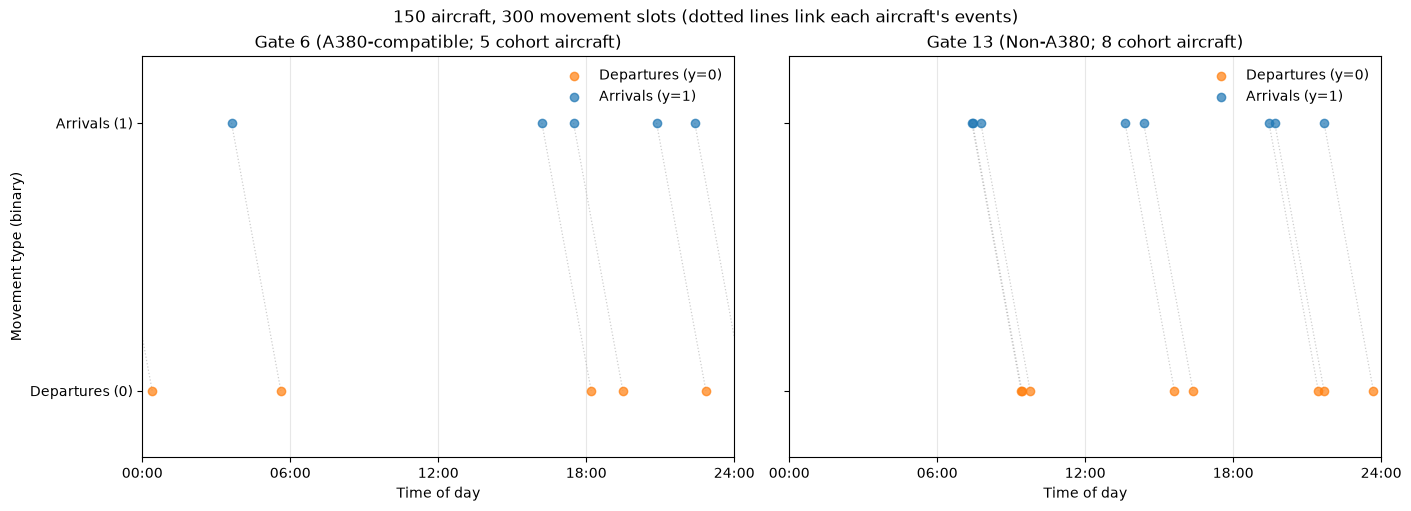

Cohort: 150 aircraft; 300 total slots (150 arrivals + 150 departures).
Displayed gates: Gate 6 (A380-compatible) and Gate 13 (non-A380); other gates are excluded from these two subplots.


In [5]:
# Form a paired arrival/departure demand picture for a 150-aircraft cohort
# Use 30 aircraft per type so the cohort is balanced across all five models.
aircraft_cohort = (
    df.groupby("model", group_keys=False)
    .head(30)
    .copy()
    .reset_index(drop=True)
)

assert aircraft_cohort["aircraft_id"].nunique() == 150
assert aircraft_cohort.groupby("model").size().eq(30).all()

time_pattern = r"^(\d{2})(\d{2})H$"
arrival_events = aircraft_cohort[["aircraft_id", "model", "gate", "scheduled_landing"]].rename(
    columns={"scheduled_landing": "scheduled_time"}
)
arrival_events["movement"] = "Arrivals"
departure_events = aircraft_cohort[["aircraft_id", "model", "gate", "scheduled_departure"]].rename(
    columns={"scheduled_departure": "scheduled_time"}
)
departure_events["movement"] = "Departures"

movement_events = pd.concat([arrival_events, departure_events], ignore_index=True)
time_parts = movement_events["scheduled_time"].astype(str).str.extract(time_pattern)
movement_events["minute_of_day"] = (
    time_parts[0].astype(int) * 60 + time_parts[1].astype(int)
)
movement_events["movement_binary"] = movement_events["movement"].map(
    {"Departures": 0, "Arrivals": 1}
)

# Each aircraft contributes exactly two correlated movement slots.
slots_per_aircraft = movement_events.groupby("aircraft_id").size()
assert len(movement_events) == 300
assert slots_per_aircraft.eq(2).all()
assert movement_events.groupby(["aircraft_id", "movement"]).size().eq(1).all()
assert movement_events["movement_binary"].isin([0, 1]).all()

# Select one A380-compatible and one standard gate represented in the cohort.
a380_gate = (
    aircraft_cohort.loc[aircraft_cohort["model"] == "A380-800", "gate"]
    .value_counts()
    .index[0]
)
standard_gate = (
    aircraft_cohort.loc[aircraft_cohort["model"] != "A380-800", "gate"]
    .value_counts()
    .index[0]
)
selected_gates = [a380_gate, standard_gate]
gate_aircraft_counts = aircraft_cohort.groupby("gate")["aircraft_id"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True, constrained_layout=True)
for ax, gate, gate_type in zip(
    axes,
    selected_gates,
    ["A380-compatible", "Non-A380"],
):
    gate_events = movement_events.loc[movement_events["gate"] == gate]
    arrival_minutes = gate_events.loc[gate_events["movement"] == "Arrivals"].set_index("aircraft_id")["minute_of_day"]
    departure_minutes = gate_events.loc[gate_events["movement"] == "Departures"].set_index("aircraft_id")["minute_of_day"]

    # Connect each aircraft's arrival to its departure; split links that cross midnight.
    for aircraft_id, arrival_minute in arrival_minutes.items():
        departure_minute = departure_minutes.loc[aircraft_id]
        if departure_minute >= arrival_minute:
            ax.plot(
                [arrival_minute, departure_minute], [1, 0],
                linestyle=":", color="0.45", alpha=0.35, linewidth=0.9, zorder=1,
            )
        else:
            cycle_duration = departure_minute + 24 * 60 - arrival_minute
            boundary_y = 1 - (24 * 60 - arrival_minute) / cycle_duration
            ax.plot(
                [arrival_minute, 24 * 60], [1, boundary_y],
                linestyle=":", color="0.45", alpha=0.35, linewidth=0.9, zorder=1,
            )
            ax.plot(
                [0, departure_minute], [boundary_y, 0],
                linestyle=":", color="0.45", alpha=0.35, linewidth=0.9, zorder=1,
            )

    for movement, binary_value, color in (
        ("Departures", 0, "tab:orange"),
        ("Arrivals", 1, "tab:blue"),
    ):
        event_slots = gate_events.loc[gate_events["movement"] == movement]
        ax.scatter(
            event_slots["minute_of_day"],
            event_slots["movement_binary"],
            color=color,
            alpha=0.7,
            s=36,
            label=f"{movement} (y={binary_value})",
            zorder=2,
        )
    ax.set_title(f"{gate} ({gate_type}; {gate_aircraft_counts[gate]} cohort aircraft)")
    ax.set_xlim(0, 24 * 60)
    ax.set_xticks(
        [0, 360, 720, 1080, 1440],
        ["00:00", "06:00", "12:00", "18:00", "24:00"],
    )
    ax.set_xlabel("Time of day")
    ax.set_yticks([0, 1], ["Departures (0)", "Arrivals (1)"])
    ax.set_ylim(-0.25, 1.25)
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="upper right", frameon=False)

axes[0].set_ylabel("Movement type (binary)")
fig.suptitle("150 aircraft, 300 movement slots (dotted lines link each aircraft's events)")
plt.show()

print(
    f"Cohort: {aircraft_cohort['aircraft_id'].nunique()} aircraft; "
    f"{len(movement_events)} total slots (150 arrivals + 150 departures)."
)
print(
    f"Displayed gates: {a380_gate} (A380-compatible) and "
    f"{standard_gate} (non-A380); other gates are excluded from these two subplots."
)


In [6]:
# Count arrivals that need an assigned gate while another aircraft still occupies it.
# Assumes Gates 1-10 are A380-compatible and Gates 11-40 serve the other aircraft.
minutes_per_day = 24 * 60
gate_order = [f"Gate {i}" for i in range(1, 41)]
gate_occupancy = {
    gate: np.zeros(minutes_per_day, dtype=np.int16)
    for gate in gate_order
}
group_occupancy = {
    "A380-800": np.zeros(minutes_per_day, dtype=np.int16),
    "Other aircraft": np.zeros(minutes_per_day, dtype=np.int16),
}
flight_intervals = {gate: [] for gate in gate_order}

for _, flight in df.iterrows():
    landing_time = str(flight["scheduled_landing"])
    departure_time = str(flight["scheduled_departure"])
    start_minute = int(landing_time[:2]) * 60 + int(landing_time[2:4])
    end_minute = int(departure_time[:2]) * 60 + int(departure_time[2:4])
    duration = (end_minute - start_minute) % minutes_per_day
    if duration == 0:
        duration = minutes_per_day

    occupied_minutes = (start_minute + np.arange(duration)) % minutes_per_day
    gate = flight["gate"]
    aircraft_group = "A380-800" if flight["model"] == "A380-800" else "Other aircraft"
    gate_occupancy[gate][occupied_minutes] += 1
    group_occupancy[aircraft_group][occupied_minutes] += 1
    flight_intervals[gate].append({
        "aircraft_id": flight["aircraft_id"],
        "start_minute": start_minute,
        "occupied_minutes": set(occupied_minutes),
    })

# Count each arrival once if one or more earlier arrivals still occupy that gate.
arrival_blockage_events = []
for _, flight in df.iterrows():
    landing_time = str(flight["scheduled_landing"])
    arrival_minute = int(landing_time[:2]) * 60 + int(landing_time[2:4])
    gate = flight["gate"]
    aircraft_group = "A380-800" if flight["model"] == "A380-800" else "Other aircraft"
    blockers = [
        interval["aircraft_id"]
        for interval in flight_intervals[gate]
        if interval["aircraft_id"] != flight["aircraft_id"]
        and interval["start_minute"] != arrival_minute
        and arrival_minute in interval["occupied_minutes"]
    ]
    if blockers:
        arrival_blockage_events.append({
            "aircraft_id": flight["aircraft_id"],
            "gate": gate,
            "aircraft_group": aircraft_group,
            "blocking_aircraft_count": len(blockers),
        })

blocked_events = pd.DataFrame(
    arrival_blockage_events,
    columns=["aircraft_id", "gate", "aircraft_group", "blocking_aircraft_count"],
)
blocked_by_group = (
    blocked_events.groupby("aircraft_group").size()
    if not blocked_events.empty
    else pd.Series(dtype=int)
)

# Keep the capacity context concise and use actual scheduled occupancy duration.
group_rows = []
for aircraft_group, occupancy in group_occupancy.items():
    compatible_gates = 10 if aircraft_group == "A380-800" else 30
    group_mask = (
        df["model"].eq("A380-800")
        if aircraft_group == "A380-800"
        else df["model"].ne("A380-800")
    )
    arrival_count = int(group_mask.sum())
    blocked_count = int(blocked_by_group.get(aircraft_group, 0))
    peak_minute = int(np.argmax(occupancy))
    demand_gate_hours = int(occupancy.sum()) / 60
    group_rows.append({
        "aircraft_group": aircraft_group,
        "arrivals": arrival_count,
        "blocked_arrivals": blocked_count,
        "blocked_pct": round(blocked_count / arrival_count * 100, 1) if arrival_count else 0,
        "compatible_gates": compatible_gates,
        "demand_gate_hours": demand_gate_hours,
        "capacity_gate_hours": compatible_gates * 24,
        "peak_simultaneous_aircraft": int(occupancy.max()),
        "peak_time": f"{peak_minute // 60:02d}:{peak_minute % 60:02d}",
    })

group_bottlenecks = pd.DataFrame(group_rows).set_index("aircraft_group")
blocked_arrivals = len(arrival_blockage_events)
blocked_predecessors = sum(
    event["blocking_aircraft_count"] for event in arrival_blockage_events
)
total_arrivals = len(df)
print(
    f"Gate-blocked arrivals: {blocked_arrivals} of {total_arrivals} "
    f"({blocked_arrivals / total_arrivals * 100:.1f}%)."
)
print(f"Preceding-aircraft blockers across those arrivals: {blocked_predecessors}.")
print("Blocked arrivals and gate capacity by aircraft group:")
display(group_bottlenecks)


Gate-blocked arrivals: 137 of 300 (45.7%).
Preceding-aircraft blockers across those arrivals: 171.
Blocked arrivals and gate capacity by aircraft group:


,arrivals,blocked_arrivals,blocked_pct,compatible_gates,demand_gate_hours,capacity_gate_hours,peak_simultaneous_aircraft,peak_time
aircraft_group,,,,,,,,
A380-800,60,21,35.0,10,120.0,240,10,08:35
Other aircraft,240,116,48.3,30,480.0,720,36,10:05


In [8]:
# Optimize gate assignments with CP-SAT: minimize conflicts, then minimize moved aircraft.
from ortools.sat.python import cp_model

solver_df = pd.read_csv("dummy_flight_schedule.csv").reset_index(drop=True)
minutes_per_day = 24 * 60
gates = sorted(solver_df["gate"].unique(), key=lambda gate: int(gate.rsplit(" ", 1)[-1]))
a380_gates = [gate for gate in gates if int(gate.rsplit(" ", 1)[-1]) <= 10]
standard_gates = [gate for gate in gates if int(gate.rsplit(" ", 1)[-1]) > 10]
aircraft_groups = [
    "A380-800" if model_name == "A380-800" else "Other aircraft"
    for model_name in solver_df["model"]
]
allowed_gates = [
    a380_gates if aircraft_group == "A380-800" else standard_gates
    for aircraft_group in aircraft_groups
]

intervals = []
for _, flight in solver_df.iterrows():
    start_text = str(flight["scheduled_landing"])
    end_text = str(flight["scheduled_departure"])
    start_minute = int(start_text[:2]) * 60 + int(start_text[2:4])
    end_minute = int(end_text[:2]) * 60 + int(end_text[2:4])
    duration = (end_minute - start_minute) % minutes_per_day
    if duration == 0:
        duration = minutes_per_day
    intervals.append({
        "start_minute": start_minute,
        "occupied_minutes": {
            (start_minute + minute_offset) % minutes_per_day
            for minute_offset in range(duration)
        },
    })

# Derive a valid conflict lower bound from peak simultaneous demand.
group_gate_counts = {"A380-800": len(a380_gates), "Other aircraft": len(standard_gates)}
group_conflict_lower_bounds = {}
for aircraft_group, gate_count in group_gate_counts.items():
    occupancy = np.zeros(minutes_per_day, dtype=np.int16)
    for flight_index, interval in enumerate(intervals):
        if aircraft_groups[flight_index] == aircraft_group:
            occupancy[list(interval["occupied_minutes"])] += 1
    minute_lower_bounds = []
    for simultaneous_flights in occupancy:
        quotient, remainder = divmod(int(simultaneous_flights), gate_count)
        minimum_pairs = (
            remainder * quotient * (quotient + 1) // 2
            + (gate_count - remainder) * quotient * (quotient - 1) // 2
        )
        minute_lower_bounds.append(minimum_pairs)
    group_conflict_lower_bounds[aircraft_group] = max(minute_lower_bounds)
conflict_lower_bound = sum(group_conflict_lower_bounds.values())

# Build conflict candidates only for overlapping flights in the same gate group.
overlapping_pairs = []
neighbors = [[] for _ in range(len(solver_df))]
for first_index in range(len(solver_df)):
    first_minutes = intervals[first_index]["occupied_minutes"]
    for second_index in range(first_index + 1, len(solver_df)):
        if aircraft_groups[first_index] != aircraft_groups[second_index]:
            continue
        if first_minutes.intersection(intervals[second_index]["occupied_minutes"]):
            overlapping_pairs.append((first_index, second_index))
            neighbors[first_index].append(second_index)
            neighbors[second_index].append(first_index)

# Greedy feasible hint: keep a current gate when it does not increase current conflicts.
heuristic_gate_indices = {}
for flight_index in sorted(range(len(solver_df)), key=lambda index: intervals[index]["start_minute"]):
    current_gate = solver_df.loc[flight_index, "gate"]
    candidates = allowed_gates[flight_index]
    if current_gate not in candidates:
        raise ValueError(f"Current gate is incompatible with {solver_df.loc[flight_index, 'aircraft_id']}")
    chosen_gate = min(
        candidates,
        key=lambda gate: (
            sum(
                allowed_gates[other_index][heuristic_gate_indices[other_index]] == gate
                for other_index in neighbors[flight_index]
                if other_index in heuristic_gate_indices
            ),
            gate != current_gate,
            gate,
        ),
    )
    heuristic_gate_indices[flight_index] = candidates.index(chosen_gate)

model = cp_model.CpModel()
gate_choice = [
    model.NewIntVar(0, len(allowed_gates[index]) - 1, f"gate_choice_{index}")
    for index in range(len(solver_df))
]
for flight_index, gate_index in heuristic_gate_indices.items():
    model.AddHint(gate_choice[flight_index], gate_index)

conflict_vars = []
for first_index, second_index in overlapping_pairs:
    conflict = model.NewBoolVar(f"conflict_{first_index}_{second_index}")
    model.Add(gate_choice[first_index] == gate_choice[second_index]).OnlyEnforceIf(conflict)
    model.Add(gate_choice[first_index] != gate_choice[second_index]).OnlyEnforceIf(conflict.Not())
    conflict_vars.append(conflict)
    model.AddHint(
        conflict,
        int(heuristic_gate_indices[first_index] == heuristic_gate_indices[second_index]),
    )

moved_vars = []
for flight_index, flight in solver_df.iterrows():
    current_index = allowed_gates[flight_index].index(flight["gate"])
    moved = model.NewBoolVar(f"moved_{flight_index}")
    model.Add(gate_choice[flight_index] == current_index).OnlyEnforceIf(moved.Not())
    model.Add(gate_choice[flight_index] != current_index).OnlyEnforceIf(moved)
    model.AddHint(moved, int(heuristic_gate_indices[flight_index] != current_index))
    moved_vars.append(moved)

# One moved aircraft can never outweigh a one-conflict improvement.
move_priority = len(solver_df) + 1
model.Minimize(move_priority * sum(conflict_vars) + sum(moved_vars))
solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 180
solver.parameters.num_search_workers = 8
solver.parameters.random_seed = 17
status = solver.Solve(model)
if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    raise RuntimeError(f"CP-SAT did not find a solution: {solver.StatusName(status)}")

optimized_gates = [
    allowed_gates[index][solver.Value(gate_choice[index])]
    for index in range(len(solver_df))
]
optimized_assignments = solver_df[["aircraft_id", "model", "gate"]].copy()
optimized_assignments["optimized_gate"] = optimized_gates
optimized_assignments["gate_changed"] = optimized_assignments["gate"] != optimized_assignments["optimized_gate"]
original_conflicts = sum(
    solver_df.loc[first_index, "gate"] == solver_df.loc[second_index, "gate"]
    for first_index, second_index in overlapping_pairs
)
optimized_conflicts = sum(
    optimized_gates[first_index] == optimized_gates[second_index]
    for first_index, second_index in overlapping_pairs
)
assert optimized_conflicts == sum(solver.Value(conflict) for conflict in conflict_vars)
assert all(
    optimized_gates[index] in allowed_gates[index]
    for index in range(len(solver_df))
)

print(f"CP-SAT status: {solver.StatusName(status)}")
print(f"Overlapping flight pairs considered: {len(overlapping_pairs)}")
print(f"Same-gate conflicts: {original_conflicts} before -> {optimized_conflicts} after")
print(f"Peak-demand conflict lower bound: {conflict_lower_bound}")
print(f"Aircraft moved to a different gate: {int(optimized_assignments['gate_changed'].sum())} of {len(solver_df)}")
print(f"Objective bound: {solver.BestObjectiveBound():.0f} (objective: {solver.ObjectiveValue():.0f})")
print("Optimized assignment summary:")
display(
    optimized_assignments.assign(aircraft_group=aircraft_groups)
    .groupby("aircraft_group")
    .agg(
        aircraft=("aircraft_id", "count"),
        moved=("gate_changed", "sum"),
        gates_used=("optimized_gate", "nunique"),
    )
)


CP-SAT status: FEASIBLE
Overlapping flight pairs considered: 5208
Same-gate conflicts: 172 before -> 7 after
Peak-demand conflict lower bound: 6
Aircraft moved to a different gate: 135 of 300
Objective bound: 69 (objective: 2242)
Optimized assignment summary:


,aircraft,moved,gates_used
aircraft_group,,,
A380-800,60,19,10
Other aircraft,240,116,30


In [7]:
# Re-run CP-SAT allowing non-A380 aircraft to use A380-compatible gates.
from ortools.sat.python import cp_model

solver_df_flexible = pd.read_csv("dummy_flight_schedule.csv").reset_index(drop=True)
minutes_per_day = 24 * 60
gates = sorted(
    solver_df_flexible["gate"].unique(),
    key=lambda gate: int(gate.rsplit(" ", 1)[-1]),
)
a380_gates = [gate for gate in gates if int(gate.rsplit(" ", 1)[-1]) <= 10]
gate_index = {gate: index for index, gate in enumerate(gates)}
a380_gate_indices = [gate_index[gate] for gate in a380_gates]
assert a380_gate_indices == list(range(len(a380_gates)))

aircraft_groups = [
    "A380-800" if model_name == "A380-800" else "Other aircraft"
    for model_name in solver_df_flexible["model"]
]
allowed_gate_indices = [
    a380_gate_indices if aircraft_group == "A380-800" else list(range(len(gates)))
    for aircraft_group in aircraft_groups
]

intervals = []
for _, flight in solver_df_flexible.iterrows():
    start_text = str(flight["scheduled_landing"])
    end_text = str(flight["scheduled_departure"])
    start_minute = int(start_text[:2]) * 60 + int(start_text[2:4])
    end_minute = int(end_text[:2]) * 60 + int(end_text[2:4])
    duration = (end_minute - start_minute) % minutes_per_day
    if duration == 0:
        duration = minutes_per_day
    intervals.append({
        "start_minute": start_minute,
        "occupied_minutes": {
            (start_minute + minute_offset) % minutes_per_day
            for minute_offset in range(duration)
        },
    })

# Count overlap pairs across all types because flexible aircraft can share A380 gates.
overlapping_pairs = []
neighbors = [[] for _ in range(len(solver_df_flexible))]
for first_index in range(len(solver_df_flexible)):
    first_minutes = intervals[first_index]["occupied_minutes"]
    for second_index in range(first_index + 1, len(solver_df_flexible)):
        if first_minutes.intersection(intervals[second_index]["occupied_minutes"]):
            overlapping_pairs.append((first_index, second_index))
            neighbors[first_index].append(second_index)
            neighbors[second_index].append(first_index)

# A safe lower bound from peak simultaneous demand and the forced A380 gate limit.
all_occupancy = np.zeros(minutes_per_day, dtype=np.int16)
a380_occupancy = np.zeros(minutes_per_day, dtype=np.int16)
for flight_index, interval in enumerate(intervals):
    occupied = list(interval["occupied_minutes"])
    all_occupancy[occupied] += 1
    if aircraft_groups[flight_index] == "A380-800":
        a380_occupancy[occupied] += 1
conflict_lower_bound = max(
    max(0, int(total) - len(gates), int(a380_total) - len(a380_gates))
    for total, a380_total in zip(all_occupancy, a380_occupancy)
)

# Greedy hint: keep an existing assignment when it does not add a conflict.
heuristic_gate_indices = {}
for flight_index in sorted(
    range(len(solver_df_flexible)),
    key=lambda index: intervals[index]["start_minute"],
):
    current_gate = solver_df_flexible.loc[flight_index, "gate"]
    current_index = gate_index[current_gate]
    candidates = allowed_gate_indices[flight_index]
    chosen_index = min(
        candidates,
        key=lambda candidate: (
            sum(
                heuristic_gate_indices[other_index] == candidate
                for other_index in neighbors[flight_index]
                if other_index in heuristic_gate_indices
            ),
            candidate != current_index,
            candidate,
        ),
    )
    heuristic_gate_indices[flight_index] = chosen_index

model = cp_model.CpModel()
gate_choice = [
    model.NewIntVar(
        min(allowed_gate_indices[index]),
        max(allowed_gate_indices[index]),
        f"flex_gate_choice_{index}",
    )
    for index in range(len(solver_df_flexible))
]
for flight_index, choices in enumerate(allowed_gate_indices):
    if aircraft_groups[flight_index] == "A380-800":
        model.Add(gate_choice[flight_index] <= max(choices))
    model.AddHint(gate_choice[flight_index], heuristic_gate_indices[flight_index])

conflict_vars = []
for first_index, second_index in overlapping_pairs:
    conflict = model.NewBoolVar(f"flex_conflict_{first_index}_{second_index}")
    model.Add(gate_choice[first_index] == gate_choice[second_index]).OnlyEnforceIf(conflict)
    model.Add(gate_choice[first_index] != gate_choice[second_index]).OnlyEnforceIf(conflict.Not())
    conflict_vars.append(conflict)
    model.AddHint(
        conflict,
        int(heuristic_gate_indices[first_index] == heuristic_gate_indices[second_index]),
    )

moved_vars = []
for flight_index, flight in solver_df_flexible.iterrows():
    current_index = gate_index[flight["gate"]]
    moved = model.NewBoolVar(f"flex_moved_{flight_index}")
    model.Add(gate_choice[flight_index] == current_index).OnlyEnforceIf(moved.Not())
    model.Add(gate_choice[flight_index] != current_index).OnlyEnforceIf(moved)
    model.AddHint(moved, int(heuristic_gate_indices[flight_index] != current_index))
    moved_vars.append(moved)

move_priority = len(solver_df_flexible) + 1
model.Minimize(move_priority * sum(conflict_vars) + sum(moved_vars))
solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 180
solver.parameters.num_search_workers = 8
solver.parameters.random_seed = 23
status = solver.Solve(model)
if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    raise RuntimeError(f"Flexible-gate CP-SAT solve failed: {solver.StatusName(status)}")

optimized_gates = [gates[solver.Value(choice)] for choice in gate_choice]
flexible_assignments = solver_df_flexible[["aircraft_id", "model", "gate"]].copy()
flexible_assignments["optimized_gate"] = optimized_gates
flexible_assignments["gate_changed"] = flexible_assignments["gate"] != flexible_assignments["optimized_gate"]
flexible_assignments["aircraft_group"] = aircraft_groups
original_conflicts = sum(
    solver_df_flexible.loc[first_index, "gate"] == solver_df_flexible.loc[second_index, "gate"]
    for first_index, second_index in overlapping_pairs
)
optimized_conflicts = sum(
    optimized_gates[first_index] == optimized_gates[second_index]
    for first_index, second_index in overlapping_pairs
)
assert optimized_conflicts == sum(solver.Value(conflict) for conflict in conflict_vars)
assert all(
    optimized_gates[index] in [gates[gate_number] for gate_number in allowed_gate_indices[index]]
    for index in range(len(solver_df_flexible))
)

flexible_assignments["uses_A380_gate"] = flexible_assignments["optimized_gate"].isin(a380_gates)
print(f"Flexible-gate CP-SAT status: {solver.StatusName(status)}")
print(f"Overlapping flight pairs considered: {len(overlapping_pairs)}")
print(f"Same-gate conflicts: {original_conflicts} before -> {optimized_conflicts} after")
print(f"Peak-demand conflict lower bound: {conflict_lower_bound}")
print(f"Aircraft moved from their original gate: {int(flexible_assignments['gate_changed'].sum())} of {len(flexible_assignments)}")
print(
    "Non-A380 aircraft assigned to A380-compatible gates:",
    int((flexible_assignments["uses_A380_gate"] & flexible_assignments["aircraft_group"].ne("A380-800")).sum()),
)
print(f"Objective bound: {solver.BestObjectiveBound():.0f} (objective: {solver.ObjectiveValue():.0f})")
print("Flexible-gate assignment summary:")
display(
    flexible_assignments.groupby("aircraft_group").agg(
        aircraft=("aircraft_id", "count"),
        moved=("gate_changed", "sum"),
        a380_compatible_gates_used=("uses_A380_gate", "sum"),
        gates_used=("optimized_gate", "nunique"),
    )
)


Flexible-gate CP-SAT status: FEASIBLE
Overlapping flight pairs considered: 7599
Same-gate conflicts: 172 before -> 6 after
Peak-demand conflict lower bound: 3
Aircraft moved from their original gate: 130 of 300
Non-A380 aircraft assigned to A380-compatible gates: 18
Objective bound: 79 (objective: 1936)
Flexible-gate assignment summary:


,aircraft,moved,a380_compatible_gates_used,gates_used
aircraft_group,,,,
A380-800,60,24,60,10
Other aircraft,240,106,18,39
